In [1]:
#!/usr/bin/env python3


from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [2]:
hists = load('../../../hists/UL_lep_monotop_v1_test_2018.scaled')
data={
    '2018':{
        'sre': 'EGamma',
        'srm': 'SingleMuon',
        'wjetm': 'SingleMuon',
        'ttbarm': 'SingleMuon',
        'wjete': 'EGamma',
        'ttbare': 'EGamma',
#         'zmcr': 'MET',
#         'zecr': 'EGamma',
#         'gcr': 'EGamma'
    }
}

data_hists   = hists['data']
bkg_hists    = hists['bkg']
signal_hists = hists['sig']

In [72]:
signal_hists['template'].identifiers('process')

[<StringBin (Mphi-1995_Mchi-1000) instance at 0x7f6e1a4000f0>,
 <StringBin (Mphi-2000_Mchi-1500) instance at 0x7f6e1a400128>,
 <StringBin (Mphi-2000_Mchi-500) instance at 0x7f6e1a400160>]

In [20]:
bkg_hists['template'].sum('region').values()

{('DY+HF',
  'nominal'): array([ 0.00000000e+00,  4.81393784e+02,  1.00333359e+03,  7.82242804e+02,
         2.82717114e+02,  2.16441484e+02,  7.69583650e+01,  9.97348979e+01,
         5.31957547e+01,  4.64207277e+00,  1.65241860e+01,  7.01432158e+00,
         5.18484060e+00,  9.33207436e-01,  7.23505550e+00,  1.39639998e+00,
        -1.28054681e-01,  6.57850955e-02, -7.80110288e-02,  1.20629106e-01]),
 ('DY+HF',
  'btagUp'): array([ 0.00000000e+00,  4.84096094e+02,  1.00883444e+03,  7.86365554e+02,
         2.86859591e+02,  2.16827809e+02,  7.85592273e+01,  1.00073287e+02,
         5.32878744e+01,  4.97063105e+00,  1.69757096e+01,  7.03491509e+00,
         5.20364817e+00,  1.04806156e+00,  7.23212171e+00,  1.39894714e+00,
        -1.39274295e-01,  6.59157760e-02, -7.38866638e-02,  1.20629106e-01]),
 ('DY+HF',
  'btagDown'): array([ 0.00000000e+00,  4.78664288e+02,  9.97708760e+02,  7.78070427e+02,
         2.78531286e+02,  2.16045777e+02,  7.52701267e+01,  9.93938088e+01,
         5.3

In [10]:
def RebinHist(histogram, axisName, rebinN=1):
    old_axis = histogram.axis(axisName)
    new_axis = hist.Bin(old_axis.name, old_axis.label, old_axis.edges()[::rebinN])
    return histogram.rebin(axisName, new_axis)

In [12]:
def SetRangeHist(histogram, axisName, lower_bound=None, upper_bound=None):
    old_axis = histogram.axis(axisName)
    lower_idx, upper_idx = None, None
    if not lower_bound is None:
        lower_idx = np.where(old_axis.edges() >= lower_bound)[0][0]
    if not upper_bound is None:
        upper_idx = np.where(old_axis.edges() <= upper_bound)[0][-1] + 1

    new_axis = hist.Bin(
        old_axis.name, old_axis.label, old_axis.edges()[lower_idx:upper_idx]
    )
    return histogram.rebin(axisName, new_axis)

In [62]:
h = bkg_hists['template'].sum('region')

In [63]:
hData = data_hists['template'].sum('region')
hData = hData.sum("process")
hData = hData.sum("systematic")
# hData = RebinHist(hData, "mT_corrected", 1)


In [54]:
h.integrate('systematic', 'nominal')

<Hist (process,mT_corrected) instance at 0x7f6e125bed68>

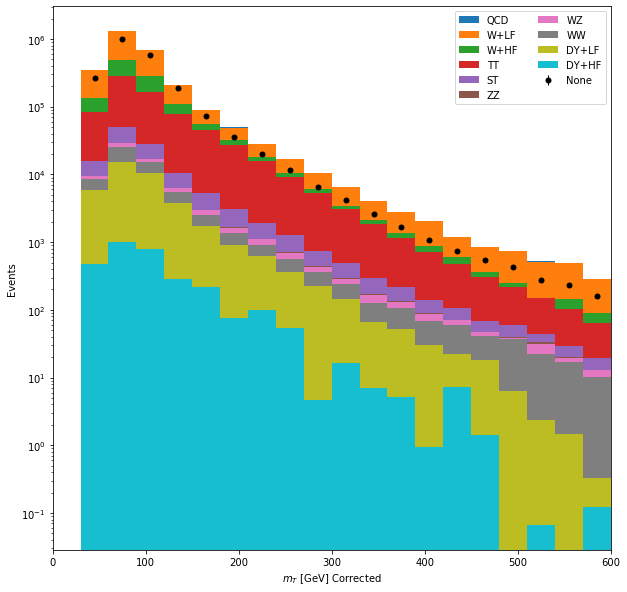

In [67]:
from coffea.hist import plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(10,10))
fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
#colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']
plot.plot1d(hData,  
        ax=ax,
        clear=False,
           error_opts=data_err_opts,
           )

plot.plot1d(h.integrate('systematic', 'nominal'),  
            overlay='process',
        ax=ax,
        clear=False,
            stack=True, 
#            error_opts=error_opts,
           )
ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
args = {'linestyle':'--', 'linewidth': 5}
ax.autoscale(axis='x', tight=True)
ax.set_yscale('log')
# if(key=='dilepmass'): ax.set_xlim(50, 130)
ax.set_ylim(.1, None)
ax.autoscale()
leg = ax.legend(ncol=2, loc='best')




In [70]:
outdir = "RootFiles"
if not os.path.exists(outdir):
    os.makedirs(outdir)

outputFile = uproot.recreate(os.path.join(outdir, "mT_Output.root"))

outputFile["dataObs"] = hData.to_hist()

process = h.axis("process").identifiers()
systematics = h.axis("systematic").identifiers()
for _process in process:
    for _systematic in systematics:
        outputFile[f"{_process}_{_systematic}"] = h.integrate("process", _process).integrate("systematic", _systematic).to_hist()

outputFile.close()

In [73]:
process = h.axis("process").identifiers()

In [74]:
process

[<StringBin (Hbb) instance at 0x7f6e1a4b36d8>,
 <StringBin (DY) instance at 0x7f6e1a4b3748>,
 <StringBin (DY+HF) instance at 0x7f6e1a4b37b8>,
 <StringBin (DY+LF) instance at 0x7f6e1a4b3828>,
 <StringBin (DY+jetsLO) instance at 0x7f6e1a4b3860>,
 <StringBin (DY+jetsNNLO) instance at 0x7f6e1a4b3898>,
 <StringBin (WW) instance at 0x7f6e1a4b3908>,
 <StringBin (WZ) instance at 0x7f6e1a4b3978>,
 <StringBin (ZZ) instance at 0x7f6e1a4b39e8>,
 <StringBin (ST) instance at 0x7f6e1a4b3a58>,
 <StringBin (TT) instance at 0x7f6e1a4b3ac8>,
 <StringBin (WJets) instance at 0x7f6e1a4b3b38>,
 <StringBin (W+HF) instance at 0x7f6e1a4b3ba8>,
 <StringBin (W+LF) instance at 0x7f6e1a4b3c18>,
 <StringBin (W+jetsLO) instance at 0x7f6e1a4b3c50>,
 <StringBin (W+jetsNNLO) instance at 0x7f6e1a4b3c88>,
 <StringBin (ZJets) instance at 0x7f6e1a4b3cf8>,
 <StringBin (Z+HF) instance at 0x7f6e1a4b3d68>,
 <StringBin (Z+LF) instance at 0x7f6e1a4b3dd8>,
 <StringBin (Z+jetsLO) instance at 0x7f6e1a4b3e10>,
 <StringBin (Z+jetsNNLO